# A1 · Preparación y Auditoría de Calidad de Datos
**Proyecto 01 — Retail Intelligence (RetailVenture C.A.)**

Este notebook cubre la actividad A1 del enunciado:
1. Carga de los seis datasets y perfilado (tipos, nulos, duplicados, cardinalidad).
2. Detección de outliers (IQR y z-score).
3. Detección de registros inconsistentes (integridad referencial, reglas temporales y reglas de negocio).
4. Métricas de calidad por dataset: **completitud, unicidad, consistencia y oportunidad**.
5. Decisiones de limpieza y transformación, justificadas.
6. Modelo dimensional (esquema de constelación / estrella).
7. Exportación de los datos limpios a `data/clean/` para las actividades A2–A4.

> Principio rector: **no se elimina información salvo que sea un error demostrable**. Los registros dudosos se *marcan* con columnas `flag_*` para que cada análisis posterior decida si incluirlos, y esa decisión quede explícita.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

RAW = Path('..')                     # los CSV originales están en la raíz del proyecto
CLEAN = Path('../data/clean'); CLEAN.mkdir(parents=True, exist_ok=True)
FIG = Path('../outputs/figuras'); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path('../outputs/tablas'); TAB.mkdir(parents=True, exist_ok=True)

FECHA_INICIO, FECHA_CORTE = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-12-31')

## 1. Carga y perfilado inicial

In [2]:
fechas = {
    'clientes': ['fecha_registro'],
    'transacciones': ['fecha'],
    'productos': [],
    'devoluciones': ['fecha_devolucion'],
    'interacciones_crm': ['fecha'],
    'campanas_marketing': ['fecha_envio'],
}
pk = {
    'clientes': 'cliente_id', 'transacciones': 'transaccion_id', 'productos': 'producto_id',
    'devoluciones': 'devolucion_id', 'interacciones_crm': 'interaccion_id', 'campanas_marketing': 'campana_id',
}
raw = {n: pd.read_csv(RAW / f'{n}.csv', parse_dates=cols, encoding='utf-8') for n, cols in fechas.items()}
cli, trx, prod, dev, crm, cam = (raw[n] for n in fechas)

pd.DataFrame({n: {'filas': len(df), 'columnas': df.shape[1],
                  'memoria_KB': round(df.memory_usage(deep=True).sum() / 1024)}
              for n, df in raw.items()}).T

,filas,columnas,memoria_KB
clientes,8000,7,2477
transacciones,50000,10,16248
productos,318,7,86
devoluciones,6724,6,1694
interacciones_crm,4684,7,1402
campanas_marketing,8820,8,2307


El enunciado habla de ~50.000 transacciones, ~8.000 clientes y **~320 productos**. El catálogo trae **318** (`PRD0001`–`PRD0318`, sin saltos en la numeración), así que se toma como el catálogo completo: el 320 del enunciado es una aproximación.

In [3]:
def perfil(df):
    # Perfil por columna: tipo, nulos explícitos, cardinalidad y ejemplos
    out = pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'nulos_%': (df.isna().mean() * 100).round(2),
        'distintos': df.nunique(),
        'ejemplos': [list(df[c].dropna().astype(str).unique()[:4]) for c in df.columns],
    })
    return out

for n, df in raw.items():
    print(f'\n=== {n} ===')
    display(perfil(df))


=== clientes ===


,tipo,nulos,nulos_%,distintos,ejemplos
cliente_id,str,0,0.0,8000,"[CLI00001, CLI00002, CLI00003, CLI00004]"
edad,int64,0,0.0,55,"[65, 23, 19, 55]"
genero,str,0,0.0,3,"[M, F, No especificado]"
ciudad,str,0,0.0,8,"[Caracas, Valencia, Mérida, Puerto La Cruz]"
segmento,str,0,0.0,5,"[Esporádico, Frecuente, Premium, Inactivo]"
fecha_registro,datetime64[us],0,0.0,730,"[2023-01-26, 2024-07-12, 2024-09-08, 2024-04-04]"
canal_adquisicion,str,0,0.0,6,"[Tienda_física, Orgánico_web, Referido, Email_..."



=== transacciones ===


,tipo,nulos,nulos_%,distintos,ejemplos
transaccion_id,str,0,0.0,50000,"[TRX0000001, TRX0000002, TRX0000003, TRX0000004]"
cliente_id,str,0,0.0,7608,"[CLI03713, CLI07240, CLI00568, CLI06802]"
fecha,datetime64[us],0,0.0,731,"[2024-01-11, 2023-08-27, 2024-07-20, 2024-04-02]"
producto_id,str,0,0.0,318,"[PRD0189, PRD0219, PRD0306, PRD0262]"
cantidad,int64,0,0.0,5,"[1, 2, 4, 3]"
precio_unitario,float64,0,0.0,317,"[6.72, 340.03, 33.94, 268.47]"
descuento,float64,0,0.0,311,"[0.044, 0.077, 0.116, 0.063]"
monto_neto,float64,0,0.0,24840,"[6.42, 313.85, 60.01, 251.56]"
canal,str,0,0.0,3,"[tienda_fisica, online, app_movil]"
metodo_pago,str,0,0.0,5,"[efectivo, tarjeta_credito, tarjeta_debito, tr..."



=== productos ===


...

,tipo,nulos,nulos_%,distintos,ejemplos
devolucion_id,str,0,0.0,6724,"[DEV000001, DEV000002, DEV000003, DEV000004]"
transaccion_id,str,0,0.0,6724,"[TRX0000015, TRX0000020, TRX0000021, TRX0000022]"
cliente_id,str,0,0.0,3679,"[CLI03995, CLI07310, CLI07961, CLI00809]"
motivo,str,0,0.0,7,"[No_cumple_expectativas, Producto_defectuoso, ..."
monto_devuelto,float64,0,0.0,5240,"[57.68, 1030.45, 753.14, 129.64]"
fecha_devolucion,datetime64[us],0,0.0,727,"[2024-08-04, 2024-06-30, 2024-07-07, 2024-01-21]"



=== interacciones_crm ===


,tipo,nulos,nulos_%,distintos,ejemplos
interaccion_id,str,0,0.0,4684,"[INT0000001, INT0000002, INT0000003, INT0000004]"
cliente_id,str,0,0.0,2400,"[CLI04116, CLI05281, CLI03254, CLI05096]"
tipo,str,0,0.0,4,"[soporte_tecnico, consulta, queja, felicitacion]"
fecha,datetime64[us],0,0.0,729,"[2024-01-22, 2023-05-14, 2023-08-19, 2024-03-21]"
canal,str,0,0.0,5,"[chat_web, email, redes_sociales, telefono]"
resolucion,str,0,0.0,4,"[escalado, resuelto, sin_resolver, parcialment..."
tiempo_respuesta_hrs,float64,0,0.0,733,"[9.8, 32.5, 34.9, 13.7]"



=== campanas_marketing ===


,tipo,nulos,nulos_%,distintos,ejemplos
campana_id,str,0,0.0,8820,"[CAM0000001, CAM0000002, CAM0000003, CAM0000004]"
cliente_id,str,0,0.0,4800,"[CLI02349, CLI07137, CLI07079, CLI02681]"
tipo_campana,str,0,0.0,5,"[social_ads, email_fidelizacion, email_descuen..."
fecha_envio,datetime64[us],0,0.0,731,"[2024-08-31, 2024-06-22, 2024-05-01, 2023-12-14]"
canal_campana,str,0,0.0,4,"[redes_sociales, email, sms, push_app]"
abierto,int64,0,0.0,2,"[0, 1]"
convertido,int64,0,0.0,2,"[0, 1]"
descuento_ofrecido,float64,0,0.0,6,"[0.0, 0.05, 0.1, 0.15]"


**Nulos explícitos:** ninguno en los seis datasets. Sin embargo, hay que buscar *nulos disfrazados*: valores que ocupan la celda pero no aportan información (p. ej. `No especificado`, cadenas vacías, `N/A`).

In [4]:
TOKENS_NULOS = {'', 'na', 'n/a', 'nan', 'null', 'none', 'no especificado', 'desconocido', 'sin dato', '-'}
filas = []
for n, df in raw.items():
    for c in df.select_dtypes(include=['object', 'string']).columns:
        s = df[c].astype(str).str.strip().str.lower()
        k = s.isin(TOKENS_NULOS).sum()
        espacios = (df[c].astype(str) != df[c].astype(str).str.strip()).sum()
        if k or espacios:
            filas.append({'dataset': n, 'columna': c, 'nulos_disfrazados': k, 'con_espacios': espacios})
pd.DataFrame(filas)

,dataset,columna,nulos_disfrazados,con_espacios
0,clientes,genero,433,0


Único nulo disfrazado: `clientes.genero = "No especificado"` (433 clientes, 5,4%). No se imputa: el género no puede inferirse de otras variables y se conserva como categoría propia. No hay espacios sobrantes ni variantes de mayúsculas en las categorías.

### Dominios de las variables categóricas

In [5]:
for n, df in raw.items():
    for c in df.select_dtypes(include=['object', 'string']).columns:
        if df[c].nunique() <= 25:
            print(f'{n}.{c}: {df[c].value_counts().to_dict()}')

clientes.genero: {'F': 3834, 'M': 3733, 'No especificado': 433}
clientes.ciudad: {'Caracas': 3170, 'Maracaibo': 1457, 'Valencia': 1201, 'Barquisimeto': 793, 'Mérida': 425, 'Puerto La Cruz': 414, 'Maturín': 314, 'San Cristóbal': 226}
clientes.segmento: {'Esporádico': 2827, 'Frecuente': 2422, 'Inactivo': 1136, 'Nuevo': 810, 'Premium': 805}
clientes.canal_adquisicion: {'Redes_sociales': 2036, 'Tienda_física': 2032, 'Orgánico_web': 1552, 'Referido': 1204, 'Email_campaña': 808, 'App_móvil': 368}


transacciones.canal: {'tienda_fisica': 22343, 'online': 19220, 'app_movil': 8437}


transacciones.metodo_pago: {'tarjeta_credito': 14984, 'tarjeta_debito': 14026, 'efectivo': 10916, 'transferencia': 6024, 'billetera_digital': 4050}
productos.categoria: {'Electrónica': 53, 'Ropa_y_Calzado': 53, 'Hogar_y_Deco': 53, 'Alimentos_y_Bebidas': 53, 'Deportes': 53, 'Belleza_y_Salud': 53}
productos.subcategoria: {'Maquillaje': 22, 'Ropa_femenina': 19, 'Computadoras': 18, 'Decoración': 18, 'Ropa_masculina': 16, 'Calzado_deportivo': 16, 'Baño': 15, 'Congelados': 15, 'Bebidas': 15, 'Accesorios_tech': 13, 'Muebles': 13, 'Suplementos': 13, 'Smartphones': 12, 'Orgánicos': 12, 'Ropa_deportiva': 12, 'Equipamiento': 12, 'Vitaminas': 12, 'Cuidado_personal': 12, 'Snacks': 11, 'Audio': 10, 'Accesorios_moda': 10, 'Calzado': 8, 'Cocina': 7, 'Skincare': 7}
devoluciones.motivo: {'No_cumple_expectativas': 2298, 'Producto_defectuoso': 1890, 'Error_en_pedido': 887, 'Demora_en_entrega': 668, 'Cambio_de_opinion': 404, 'Talla_incorrecta': 305, 'Fraude_reportado': 272}
interacciones_crm.tipo: {'queja'

## 2. Duplicados

In [6]:
claves_logicas = {
    'clientes': None,
    'transacciones': ['cliente_id', 'fecha', 'producto_id', 'cantidad', 'monto_neto', 'canal'],
    'productos': ['nombre'],
    'devoluciones': ['transaccion_id'],          # una transacción no debería devolverse dos veces
    'interacciones_crm': ['cliente_id', 'tipo', 'fecha', 'canal'],
    'campanas_marketing': ['cliente_id', 'tipo_campana', 'fecha_envio'],
}
dup = []
for n, df in raw.items():
    dup.append({'dataset': n,
                'filas_identicas': df.duplicated().sum(),
                'pk_duplicada': df[pk[n]].duplicated().sum(),
                'dup_logicos': df.duplicated(claves_logicas[n]).sum() if claves_logicas[n] else 0})
pd.DataFrame(dup)

,dataset,filas_identicas,pk_duplicada,dup_logicos
0,clientes,0,0,0
1,transacciones,0,0,0
2,productos,0,0,0
3,devoluciones,0,0,0
4,interacciones_crm,0,0,0
5,campanas_marketing,0,0,1


In [7]:
cam[cam.duplicated(['cliente_id', 'tipo_campana', 'fecha_envio'], keep=False)]

,campana_id,cliente_id,tipo_campana,fecha_envio,canal_campana,abierto,convertido,descuento_ofrecido
4457,CAM0004458,CLI01899,email_descuento,2024-06-13,email,0,0,0.15
4459,CAM0004460,CLI01899,email_descuento,2024-06-13,email,1,1,0.05


Solo hay **1 duplicado lógico**: el cliente `CLI01899` recibió dos `email_descuento` el mismo día con descuentos distintos (15% y 5%), y solo convirtió el segundo. Como tienen ID distinto, descuento distinto y resultado distinto, no es una fila repetida por error de carga: parece un doble envío, o una prueba A/B. **Se conservan los dos y se marcan** (`flag_envio_duplicado`), porque borrar uno cambiaría la tasa de conversión del descuento que se elimine.

## 3. Outliers

In [8]:
def outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    return {'n': len(s), 'min': s.min(), 'p50': s.median(), 'p99': s.quantile(.99), 'max': s.max(),
            'lim_sup_IQR': q3 + 1.5 * iqr,
            'outliers_IQR': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            'outliers_z>3': int((z.abs() > 3).sum())}

variables = {
    'clientes.edad': cli.edad, 'transacciones.cantidad': trx.cantidad,
    'transacciones.precio_unitario': trx.precio_unitario, 'transacciones.descuento': trx.descuento,
    'transacciones.monto_neto': trx.monto_neto, 'productos.costo': prod.costo,
    'productos.margen_bruto_pct': prod.margen_bruto_pct, 'devoluciones.monto_devuelto': dev.monto_devuelto,
    'crm.tiempo_respuesta_hrs': crm.tiempo_respuesta_hrs, 'campanas.descuento_ofrecido': cam.descuento_ofrecido,
}
tabla_out = pd.DataFrame({k: outliers(v) for k, v in variables.items()}).T.round(2)
tabla_out

,n,min,p50,p99,max,lim_sup_IQR,outliers_IQR,outliers_z>3
clientes.edad,8000.0,18.00,45.00,72.00,72.00,101.00,0.0,0.0
transacciones.cantidad,50000.0,1.00,1.00,5.00,5.00,3.50,5042.0,0.0
transacciones.precio_unitario,50000.0,4.04,116.60,1132.89,1186.64,662.62,2509.0,1086.0
transacciones.descuento,50000.0,0.00,0.03,0.24,0.34,0.20,2144.0,496.0
transacciones.monto_neto,50000.0,3.10,163.99,2422.11,5840.92,998.50,4138.0,1195.0
productos.costo,318.0,2.68,69.30,952.74,996.20,414.58,27.0,8.0
productos.margen_bruto_pct,318.0,8.50,35.50,51.23,56.00,65.76,0.0,0.0
devoluciones.monto_devuelto,6724.0,3.16,171.59,2842.27,5552.95,1028.71,615.0,173.0
crm.tiempo_respuesta_hrs,4684.0,0.40,12.00,109.33,518.60,48.90,352.0,82.0
campanas.descuento_ofrecido,8820.0,0.00,0.10,0.25,0.25,0.43,0.0,0.0


C:\Windows\Temp\ipykernel_34776\873481466.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, widths=.6, flierprops=dict(marker='.', markersize=3, alpha=.4))
C:\Windows\Temp\ipykernel_34776\873481466.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, widths=.6, flierprops=dict(marker='.', markersize=3, alpha=.4))
C:\Windows\Temp\ipykernel_34776\873481466.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, widths=.6, flierprops=dict(marker='.', markersize=3, alpha=.4))
C:\Windows\Temp\ipykernel_34776\873481466.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Ma

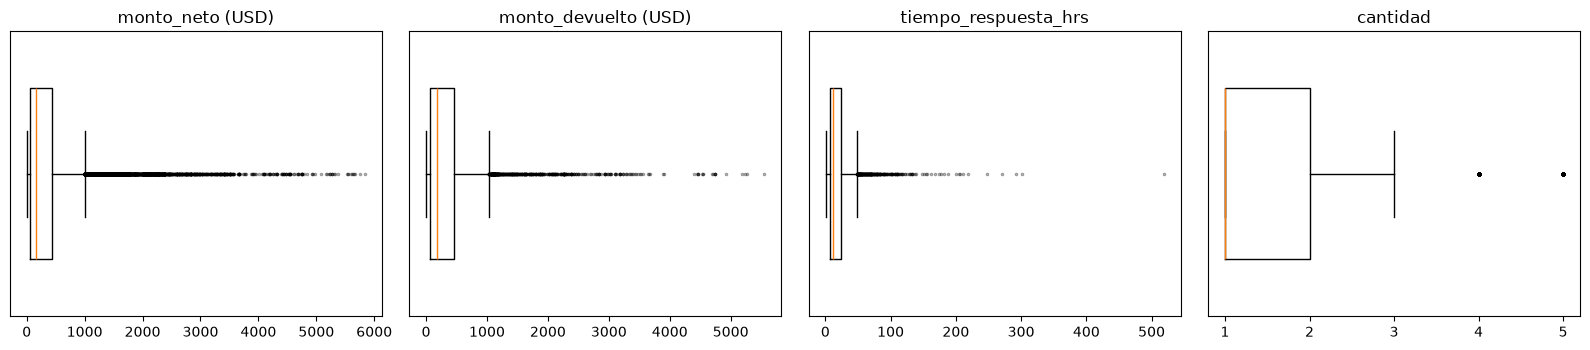

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (k, s) in zip(axes, [('monto_neto (USD)', trx.monto_neto), ('monto_devuelto (USD)', dev.monto_devuelto),
                             ('tiempo_respuesta_hrs', crm.tiempo_respuesta_hrs), ('cantidad', trx.cantidad)]):
    ax.boxplot(s, vert=False, widths=.6, flierprops=dict(marker='.', markersize=3, alpha=.4))
    ax.set_title(k); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / 'a1_outliers_boxplots.png', dpi=150); plt.show()

In [10]:
# ¿Los outliers de monto_neto son errores o ventas legítimas de productos caros?
q3, q1 = trx.monto_neto.quantile([.75, .25]); lim = q3 + 1.5 * (q3 - q1)
out_m = trx[trx.monto_neto > lim].merge(prod[['producto_id', 'categoria']], on='producto_id')
print('Outliers de monto_neto por categoría:'); print(out_m.categoria.value_counts(normalize=True).round(3))
print('\n¿El monto cuadra con precio × cantidad × (1 − descuento)?',
      np.allclose(out_m.monto_neto, out_m.precio_unitario * out_m.cantidad * (1 - out_m.descuento), atol=0.02))
print('\nTiempos de respuesta > 7 días (168 h):'); display(crm[crm.tiempo_respuesta_hrs > 168].sort_values('tiempo_respuesta_hrs', ascending=False).head(15))

Outliers de monto_neto por categoría:
categoria
Electrónica     0.646
Hogar_y_Deco    0.282
Deportes        0.072
Name: proportion, dtype: float64

¿El monto cuadra con precio × cantidad × (1 − descuento)? True

Tiempos de respuesta > 7 días (168 h):


,interaccion_id,cliente_id,tipo,fecha,canal,resolucion,tiempo_respuesta_hrs
4365,INT0004366,CLI02402,consulta,2023-04-30,email,resuelto,518.6
3321,INT0003322,CLI04900,consulta,2024-06-24,redes_sociales,resuelto,301.5
252,INT0000253,CLI00120,queja,2024-09-12,redes_sociales,sin_resolver,292.1
614,INT0000615,CLI07986,felicitacion,2024-01-17,chat_web,sin_resolver,270.1
3393,INT0003394,CLI02097,queja,2024-03-20,chat_web,sin_resolver,247.7
3877,INT0003878,CLI05903,queja,2024-04-08,telefono,sin_resolver,219.1
2012,INT0002013,CLI01424,consulta,2024-08-30,chat_web,resuelto,211.5
3456,INT0003457,CLI01848,queja,2024-03-17,chat_web,escalado,206.5
3301,INT0003302,CLI04085,consulta,2024-07-21,email,resuelto,205.5
3275,INT0003276,CLI08000,consulta,2023-06-15,chat_web,parcialmente_resuelto,200.8


**Interpretación**

| Variable | Diagnóstico | Decisión |
|---|---|---|
| `monto_neto`, `precio_unitario`, `monto_devuelto` | Los outliers por IQR son casi todos de Electrónica y el monto cuadra exactamente con precio × cantidad × (1 − descuento). Son **ventas reales de productos caros**, no errores. Es una distribución asimétrica a la derecha, típica del retail. | Se **conservan**. En los análisis se reportan medianas junto a las medias y se marcan con `flag_outlier_monto`. |
| `cantidad` | 1 a 5 unidades: el IQR marca 4 y 5 solo porque el 55% de las compras son de 1 unidad. | No es outlier real; se conserva sin marca. |
| `tiempo_respuesta_hrs` | Mediana de 12 h, p99 de ~109 h y máximo de 518 h (21 días). Valores positivos y plausibles (casos escalados). | Se **conservan** porque son señal de mal servicio, que es justo lo que A3 analiza. Se marcan los > 168 h (`flag_respuesta_extrema`) y los promedios se calculan *winsorizados* al p99 para que 15 casos no muevan la media. |
| `edad`, `margen`, `descuentos` | Dentro de rangos válidos (edad 18–72, margen 8,5–56%, descuento 0–34,5%). | Sin acción. |

## 4. Registros inconsistentes

### 4.1 Integridad referencial (claves foráneas)

In [11]:
fk = pd.DataFrame([
    ('transacciones.cliente_id → clientes', (~trx.cliente_id.isin(cli.cliente_id)).sum(), len(trx)),
    ('transacciones.producto_id → productos', (~trx.producto_id.isin(prod.producto_id)).sum(), len(trx)),
    ('devoluciones.transaccion_id → transacciones', (~dev.transaccion_id.isin(trx.transaccion_id)).sum(), len(dev)),
    ('devoluciones.cliente_id → clientes', (~dev.cliente_id.isin(cli.cliente_id)).sum(), len(dev)),
    ('interacciones_crm.cliente_id → clientes', (~crm.cliente_id.isin(cli.cliente_id)).sum(), len(crm)),
    ('campanas_marketing.cliente_id → clientes', (~cam.cliente_id.isin(cli.cliente_id)).sum(), len(cam)),
], columns=['relación', 'huérfanos', 'total'])
fk

,relación,huérfanos,total
0,transacciones.cliente_id → clientes,0,50000
1,transacciones.producto_id → productos,0,50000
2,devoluciones.transaccion_id → transacciones,0,6724
3,devoluciones.cliente_id → clientes,0,6724
4,interacciones_crm.cliente_id → clientes,0,4684
5,campanas_marketing.cliente_id → clientes,0,8820


La integridad referencial es **perfecta**: no hay devoluciones sin transacción de origen ni registros que apunten a clientes o productos inexistentes.

### 4.2 Reglas de negocio y reglas temporales

In [12]:
# Uniones auxiliares
dv = dev.merge(trx[['transaccion_id', 'cliente_id', 'fecha', 'monto_neto', 'producto_id']],
               on='transaccion_id', how='left', suffixes=('', '_trx')).merge(prod[['producto_id', 'categoria']], on='producto_id')
tp = trx.merge(prod, on='producto_id', how='left')
reg = cli.set_index('cliente_id').fecha_registro
primera_compra = trx.groupby('cliente_id').fecha.min()

# Ventana de atribución de campañas: compra del cliente en los 30 días posteriores al envío
VENTANA = 30
cx = cam[['campana_id', 'cliente_id', 'fecha_envio']].merge(trx[['cliente_id', 'fecha', 'monto_neto']], on='cliente_id')
cx = cx[(cx.fecha >= cx.fecha_envio) & (cx.fecha <= cx.fecha_envio + pd.Timedelta(days=VENTANA))]
cam_con_compra = set(cx.campana_id)

reglas = {
  'clientes': {
    'R01 edad entre 18 y 100': cli.edad.between(18, 100),
    'R02 fecha_registro dentro del período': cli.fecha_registro.between(FECHA_INICIO, FECHA_CORTE),
    'R03 fecha_registro ≤ primera compra': ~(cli.cliente_id.map(primera_compra) < cli.fecha_registro),
  },
  'transacciones': {
    'R04 precio_unitario = precio_lista del catálogo': np.isclose(tp.precio_unitario, tp.precio_lista, atol=0.01),
    'R05 monto_neto = cant × precio × (1 − desc)': np.isclose(trx.monto_neto, trx.cantidad * trx.precio_unitario * (1 - trx.descuento), atol=0.02),
    'R06 cantidad > 0 y descuento en [0, 1)': (trx.cantidad > 0) & trx.descuento.between(0, 0.999),
    'R07 fecha de compra ≥ fecha_registro del cliente': trx.fecha.values >= trx.cliente_id.map(reg).values,
  },
  'productos': {
    'R08 costo < precio_lista': prod.costo < prod.precio_lista,
    'R09 margen_bruto_pct = (precio − costo)/precio (±0,1 pp)': ((prod.precio_lista - prod.costo) / prod.precio_lista * 100 - prod.margen_bruto_pct).abs() <= 0.1,
  },
  'devoluciones': {
    'R10 cliente coincide con el de la transacción': dv.cliente_id == dv.cliente_id_trx,
    'R11 fecha_devolucion ≥ fecha de compra': dv.fecha_devolucion >= dv.fecha,
    'R12 monto_devuelto ≤ monto_neto': dv.monto_devuelto <= dv.monto_neto + 0.01,
    'R13 motivo "Talla_incorrecta" solo en Ropa_y_Calzado': ~((dv.motivo == 'Talla_incorrecta') & (dv.categoria != 'Ropa_y_Calzado')),
  },
  'interacciones_crm': {
    'R14 tiempo_respuesta_hrs > 0': crm.tiempo_respuesta_hrs > 0,
    'R15 felicitación sin estado de resolución': ~((crm.tipo == 'felicitacion') & crm.resolucion.notna()),
    'R16 fecha ≥ fecha_registro del cliente': crm.fecha.values >= crm.cliente_id.map(reg).values,
  },
  'campanas_marketing': {
    'R17 canal coherente con tipo de campaña': cam.canal_campana == cam.tipo_campana.map({'email_descuento': 'email', 'email_fidelizacion': 'email', 'push_reactivacion': 'push_app', 'sms_oferta_flash': 'sms', 'social_ads': 'redes_sociales'}),
    'R18 convertido ⇒ abierto': ~((cam.convertido == 1) & (cam.abierto == 0)),
    'R19 convertido ⇒ compra en ≤30 días tras el envío': ~((cam.convertido == 1) & ~cam.campana_id.isin(cam_con_compra)),
    'R20 fecha_envio ≥ fecha_registro del cliente': cam.fecha_envio.values >= cam.cliente_id.map(reg).values,
  },
}
tabla_reglas = pd.DataFrame([{'dataset': ds, 'regla': r, 'incumplen': int((~pd.Series(ok)).sum()), 'total': len(ok),
                              '%_cumple': round(pd.Series(ok).mean() * 100, 2)}
                             for ds, rr in reglas.items() for r, ok in rr.items()])
tabla_reglas

,dataset,regla,incumplen,total,%_cumple
0,clientes,R01 edad entre 18 y 100,0,8000,100.00
1,clientes,R02 fecha_registro dentro del período,0,8000,100.00
2,clientes,R03 fecha_registro ≤ primera compra,5803,8000,27.46
3,transacciones,R04 precio_unitario = precio_lista del catálogo,0,50000,100.00
4,transacciones,R05 monto_neto = cant × precio × (1 − desc),0,50000,100.00
5,transacciones,"R06 cantidad > 0 y descuento en [0, 1)",0,50000,100.00
6,transacciones,R07 fecha de compra ≥ fecha_registro del cliente,24972,50000,50.06
7,productos,R08 costo < precio_lista,0,318,100.00
8,productos,R09 margen_bruto_pct = (precio − costo)/precio...,0,318,100.00
9,devoluciones,R10 cliente coincide con el de la transacción,0,6724,100.00


### 4.3 Análisis de las inconsistencias detectadas

**a) `fecha_registro` posterior a la actividad del cliente (R03, R07, R16, R20).** Es la inconsistencia más grave:

Transacciones anteriores al registro: 24,972 (49.9%)
Clientes compradores con primera compra antes del registro: 5,803 de 7,608
Días de adelanto (compra antes del registro):
count    24972.0
mean       246.5
std        174.5
min          1.0
25%         98.0
50%        216.0
75%        371.0
max        728.0
dtype: float64


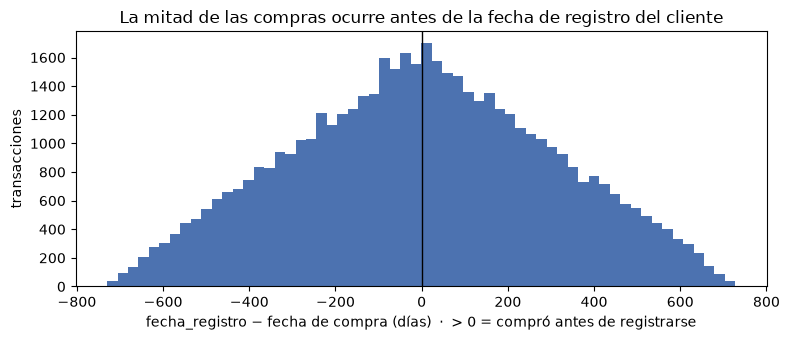

In [13]:
gap = (trx.cliente_id.map(reg) - trx.fecha).dt.days
print(f"Transacciones anteriores al registro: {(gap > 0).sum():,} ({(gap > 0).mean():.1%})")
print(f"Clientes compradores con primera compra antes del registro: {(primera_compra < reg.reindex(primera_compra.index)).sum():,} de {len(primera_compra):,}")
print('Días de adelanto (compra antes del registro):'); print(gap[gap > 0].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gap, bins=60, color='#4C72B0'); ax.axvline(0, color='k', lw=1)
ax.set_xlabel('fecha_registro − fecha de compra (días)  ·  > 0 = compró antes de registrarse'); ax.set_ylabel('transacciones')
ax.set_title('La mitad de las compras ocurre antes de la fecha de registro del cliente')
plt.tight_layout(); plt.savefig(FIG / 'a1_registro_vs_compra.png', dpi=150); plt.show()

La diferencia se reparte de forma casi uniforme hasta 728 días. No parece un desfase fijo (por ejemplo, de zona horaria o de formato de fecha), sino que `fecha_registro` **no guarda relación con la actividad real del cliente**. Hipótesis: es la fecha en que el cliente creó su cuenta en la plataforma o en el programa de fidelización, mientras que antes compraba como invitado o en tienda.

**Decisión:** eliminar esas filas significaría perder el 50% de las ventas, así que **no se eliminan**. En su lugar:
- se marcan con `flag_antes_registro`;
- se crea `fecha_alta_efectiva = mín(fecha_registro, primer evento observado)` en la dimensión cliente;
- la **antigüedad del cliente** (que se usa en el CLV) se calcula desde la primera compra, no desde `fecha_registro`.

**b) Conversiones sin compra verificable (R19).** El 77,5% de las campañas marcadas como `convertido = 1` **no tiene ninguna transacción del cliente en los 30 días siguientes al envío**:

In [14]:
conv = cam[cam.convertido == 1]
sig = (cam[['campana_id', 'cliente_id', 'fecha_envio']].merge(trx[['cliente_id', 'fecha']], on='cliente_id')
       .query('fecha >= fecha_envio').assign(dias=lambda x: (x.fecha - x.fecha_envio).dt.days)
       .groupby('campana_id').dias.min())
conv_d = conv.campana_id.map(sig)
print(f"Conversiones declaradas: {len(conv)}")
print(f"  con compra en ≤ {VENTANA} días: {(conv_d <= VENTANA).sum()} ({(conv_d <= VENTANA).mean():.1%})")
print(f"  con compra posterior pero > {VENTANA} días: {((conv_d > VENTANA)).sum()}")
print(f"  sin ninguna compra posterior: {conv_d.isna().sum()}")
nc = cam[cam.convertido == 0].campana_id.map(sig)
print(f"\nComparativo: campañas NO convertidas con compra en ≤ {VENTANA} días: {(nc <= VENTANA).mean():.1%}")

Conversiones declaradas: 797
  con compra en ≤ 30 días: 179 (22.5%)
  con compra posterior pero > 30 días: 434
  sin ninguna compra posterior: 184

Comparativo: campañas NO convertidas con compra en ≤ 30 días: 20.1%


El flag `convertido` del sistema de marketing **no se refleja de forma consistente en las transacciones**. Además, las campañas *no* convertidas tienen una tasa de compra a 30 días parecida, lo que indica que el flag no es un buen indicador de compra incremental.

**Decisión:** se mantiene `convertido` como la métrica oficial (es el dato que reporta el negocio y el que menciona el caso: 22% → 11%), y se crea `flag_conversion_verificada` (compra en ≤ 30 días) para:
- calcular el **monto de compra convertida** del ROI (A4) solo con compras reales;
- probar la robustez de las conclusiones de marketing con las dos definiciones.

Esta diferencia se reporta como **limitación del dato** y se recomienda auditar el *tracking* de atribución.

**c) Felicitaciones con estado de resolución (R15).** Una felicitación no es un caso que haya que resolver, así que `sin_resolver` o `escalado` no tienen sentido semántico. **Decisión:** `resolucion = "no_aplica"` para las 233 felicitaciones, y se excluyen del análisis de quejas no resueltas (A3).

**d) Duplicado lógico de campaña.** Ver la sección 2: se conserva y se marca.

### 4.4 Contraste con las premisas del caso
Antes de construir el relato, verificamos si los datos sostienen las tres cifras que da la gerencia:

In [15]:
trx['trimestre'] = trx.fecha.dt.to_period('Q')
cam['trimestre'] = cam.fecha_envio.dt.to_period('Q')
q = (trx.assign(devuelta=trx.transaccion_id.isin(dev.transaccion_id))
        .groupby('trimestre').agg(transacciones=('transaccion_id', 'size'), ticket_prom=('monto_neto', 'mean'),
                                  tasa_devolucion=('devuelta', 'mean')))
q['conversion_campanas'] = cam.groupby('trimestre').convertido.mean()
q['ticket_var_interanual'] = q.ticket_prom.pct_change(4)
display(q.style.format({'ticket_prom': '{:.2f}', 'tasa_devolucion': '{:.1%}', 'conversion_campanas': '{:.1%}', 'ticket_var_interanual': '{:+.1%}'}))
q.to_csv(TAB / 'a1_premisas_trimestrales.csv')

,transacciones,ticket_prom,tasa_devolucion,conversion_campanas,ticket_var_interanual
trimestre,,,,,
2023Q1,6043,350.43,13.2%,11.3%,+nan%
2023Q2,6295,344.02,13.6%,12.3%,+nan%
2023Q3,6152,363.25,13.0%,11.2%,+nan%
2023Q4,6300,347.69,13.8%,10.2%,+nan%
2024Q1,6320,340.39,13.3%,7.9%,-2.9%
2024Q2,6342,341.73,13.3%,6.8%,-0.7%
2024Q3,6251,348.89,13.8%,7.1%,-4.0%
2024Q4,6297,347.02,13.5%,5.6%,-0.2%


| Premisa del caso | Lo que muestran los datos | Lectura |
|---|---|---|
| Ticket promedio −8% interanual | Variación interanual por trimestre entre −4% y +1%; 2024 vs. 2023 ≈ −1,9% (351,3 → 344,5 USD) | **No se confirma** en la magnitud indicada. |
| Devoluciones al 14% en el último trimestre | 13,5% en 2024-Q4, estable entre 13% y 14% en los 8 trimestres | Nivel **confirmado**, pero **no es un aumento**: el problema es estructural, no reciente. |
| Conversión de 22% a 11% en 18 meses | 11,3% (2023-Q1) → 5,6% (2024-Q4) | La **caída a la mitad se confirma**. Medida sobre campañas *abiertas*, la conversión pasa de ~30–33% (2023) a 15,4% (2024-Q4): la gerencia probablemente usa otra base de cálculo (ver celda siguiente). |

Esto es importante para la defensa: el relato va a partir de lo que **muestran los datos**, no de las premisas de la gerencia.

In [16]:
# ¿La conversión del caso (22%) corresponde a conversión sobre campañas abiertas?
ab = cam[cam.abierto == 1].groupby('trimestre').convertido.mean()
print('Conversión sobre campañas ABIERTAS por trimestre:'); print(ab.map('{:.1%}'.format).to_string())

Conversión sobre campañas ABIERTAS por trimestre:
trimestre
2023Q1    29.8%
2023Q2    33.2%
2023Q3    32.5%
2023Q4    30.8%
2024Q1    20.6%
2024Q2    20.3%
2024Q3    19.4%
2024Q4    15.4%
Freq: Q-DEC


Sobre campañas abiertas, la conversión **cae a la mitad** (≈31% → 15%), igual que en la base total (11% → 5,6%). Sea cual sea la definición, el deterioro relativo (−50%) es el mismo, y ese es el hecho relevante para el relato. En A4 se reportan las dos bases.

## 5. Métricas de calidad por dataset

Definiciones (todas en %; 100% = calidad perfecta):

- **Completitud** = 1 − (celdas nulas explícitas + nulos disfrazados) / celdas totales.
- **Unicidad** = 1 − (registros con PK duplicada + duplicados lógicos) / registros.
- **Consistencia** = % de registros que cumplen **todas** las reglas de su dataset (integridad referencial + reglas R01–R20). También se reporta la consistencia **sin** la regla de `fecha_registro`, para separar el efecto de ese único atributo.
- **Oportunidad** = % de registros que llegan **a tiempo y dentro de la ventana de análisis**: la fecha del evento cae entre 2023-01-01 y 2024-12-31 y se cumple la latencia esperada (devolución ≤ 30 días después de la compra; respuesta CRM ≤ 168 h; productos: precio vigente igual al transaccionado). Se acompaña con la **frescura**: días entre el último registro y la fecha de corte.

In [17]:
nulos_disfrazados = {'clientes': (cli.genero == 'No especificado').sum()}
regla_registro = {'R03 fecha_registro ≤ primera compra', 'R07 fecha de compra ≥ fecha_registro del cliente',
                  'R16 fecha ≥ fecha_registro del cliente', 'R20 fecha_envio ≥ fecha_registro del cliente'}
fk_ok = {
    'clientes': pd.Series(True, index=cli.index),
    'transacciones': trx.cliente_id.isin(cli.cliente_id) & trx.producto_id.isin(prod.producto_id),
    'productos': pd.Series(True, index=prod.index),
    'devoluciones': dev.transaccion_id.isin(trx.transaccion_id) & dev.cliente_id.isin(cli.cliente_id),
    'interacciones_crm': crm.cliente_id.isin(cli.cliente_id),
    'campanas_marketing': cam.cliente_id.isin(cli.cliente_id),
}
en_ventana = lambda s: s.between(FECHA_INICIO, FECHA_CORTE)
oportunidad = {
    'clientes': en_ventana(cli.fecha_registro),
    'transacciones': en_ventana(trx.fecha),
    'productos': prod.producto_id.isin(tp.loc[np.isclose(tp.precio_unitario, tp.precio_lista), 'producto_id']),
    'devoluciones': en_ventana(dv.fecha_devolucion) & ((dv.fecha_devolucion - dv.fecha).dt.days <= 30),
    'interacciones_crm': en_ventana(crm.fecha) & (crm.tiempo_respuesta_hrs <= 168),
    'campanas_marketing': en_ventana(cam.fecha_envio),
}
ultima_fecha = {'clientes': cli.fecha_registro.max(), 'transacciones': trx.fecha.max(), 'productos': pd.NaT,
                'devoluciones': dev.fecha_devolucion.max(), 'interacciones_crm': crm.fecha.max(), 'campanas_marketing': cam.fecha_envio.max()}

filas = []
for n, df in raw.items():
    celdas = df.shape[0] * df.shape[1]
    completitud = 1 - (df.isna().sum().sum() + nulos_disfrazados.get(n, 0)) / celdas
    dup_l = df.duplicated(claves_logicas[n]).sum() if claves_logicas[n] else 0
    unicidad = 1 - (df[pk[n]].duplicated().sum() + dup_l) / len(df)
    todas = pd.concat([pd.Series(np.asarray(v), index=df.index) for v in reglas[n].values()] + [fk_ok[n]], axis=1).all(axis=1)
    sin_reg = pd.concat([pd.Series(np.asarray(v), index=df.index) for r, v in reglas[n].items() if r not in regla_registro] + [fk_ok[n]], axis=1).all(axis=1)
    filas.append({'dataset': n, 'registros': len(df),
                  'completitud_%': completitud * 100, 'unicidad_%': unicidad * 100,
                  'consistencia_%': todas.mean() * 100, 'consistencia_sin_fecha_registro_%': sin_reg.mean() * 100,
                  'oportunidad_%': oportunidad[n].mean() * 100,
                  'frescura_dias': (FECHA_CORTE - ultima_fecha[n]).days if pd.notna(ultima_fecha[n]) else None})
calidad = pd.DataFrame(filas).set_index('dataset').round(2)
calidad.to_csv(TAB / 'a1_metricas_calidad.csv')
calidad

,registros,completitud_%,unicidad_%,consistencia_%,consistencia_sin_fecha_registro_%,oportunidad_%,frescura_dias
dataset,,,,,,,
clientes,8000,99.23,100.00,27.46,100.00,100.00,0.0
transacciones,50000,100.00,100.00,50.06,100.00,100.00,0.0
productos,318,100.00,100.00,100.00,100.00,100.00,NaN
devoluciones,6724,100.00,100.00,100.00,100.00,100.00,0.0
interacciones_crm,4684,100.00,100.00,45.64,95.03,99.68,0.0
campanas_marketing,8820,100.00,99.99,47.02,92.99,100.00,0.0


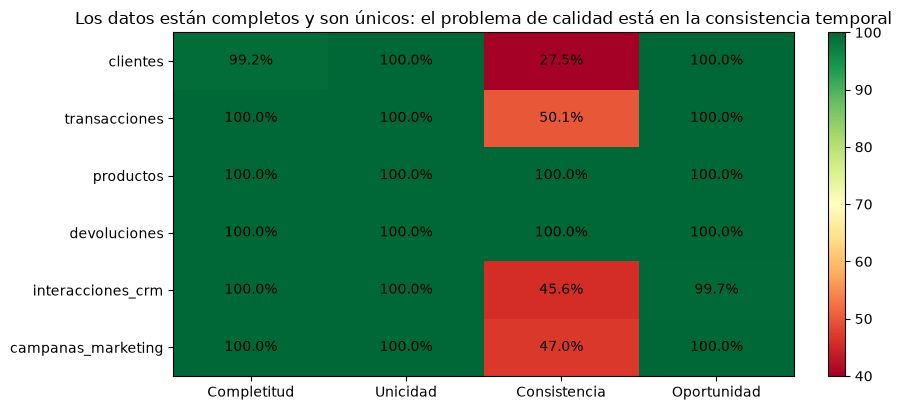

In [18]:
dims = ['completitud_%', 'unicidad_%', 'consistencia_%', 'oportunidad_%']
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(calidad[dims].values, cmap='RdYlGn', vmin=40, vmax=100, aspect='auto')
ax.set_xticks(range(4), [d.replace('_%', '').capitalize() for d in dims]); ax.set_yticks(range(len(calidad)), calidad.index)
for (r, c_), v in np.ndenumerate(calidad[dims].values):
    ax.text(c_, r, f'{v:.1f}%', ha='center', va='center', fontsize=10)
ax.set_title('Los datos están completos y son únicos: el problema de calidad está en la consistencia temporal')
plt.colorbar(im, ax=ax, fraction=.03); plt.tight_layout(); plt.savefig(FIG / 'a1_metricas_calidad.png', dpi=150); plt.show()

**Lectura:** la completitud y la unicidad son prácticamente perfectas. La calidad se cae en **consistencia**, y casi todo se explica por un solo atributo (`clientes.fecha_registro`), que contamina clientes, transacciones, CRM y campañas. Si se excluye esa regla, todos los datasets quedan en 95% o más, salvo campañas (93%), que sigue penalizada por las conversiones sin compra verificable (R19). **Conclusión: los datos sirven para el análisis, pero hay que tratar con cautela dos campos: `fecha_registro` y `convertido`.**

## 6. Limpieza y transformación

In [19]:
decisiones = pd.DataFrame([
    ('clientes', 'genero = "No especificado" (433)', 'Conservar como categoría propia; no imputar', 'No es inferible desde otras variables; imputar introduciría un sesgo.'),
    ('clientes', 'fecha_registro posterior a la primera compra (5.803 clientes)', 'Conservar; crear fecha_alta_efectiva = mín(registro, primer evento) y antiguedad_dias', 'Eliminar invalidaría el 50% de las ventas; la actividad transaccional es más confiable que un campo de alta.'),
    ('clientes', '392 clientes sin compras', 'Conservar; flag_sin_compras', 'Son relevantes para marketing (reciben campañas) y para el churn.'),
    ('transacciones', '24.972 compras anteriores a fecha_registro', 'Conservar; flag_antes_registro', 'Mismo motivo: el error está en el atributo del cliente, no en la transacción.'),
    ('transacciones', 'Outliers de monto_neto (IQR)', 'Conservar; flag_outlier_monto', 'Ventas legítimas de alto valor (Electrónica); el monto cuadra exactamente.'),
    ('transacciones', 'Variables derivadas', 'Calcular ingreso_bruto, costo_total, margen_bruto, margen_bruto_pct, descuento_monto, flag_devuelta, monto_devuelto, margen_neto (base: el producto devuelto se recupera salvo defecto o fraude) y margen_neto_pesimista', 'El margen no viene en las transacciones; es la base del análisis de rentabilidad (A2) y de fugas (A3).'),
    ('devoluciones', 'Variables derivadas', 'dias_a_devolucion, categoria, segmento', 'Facilita el análisis de patrones de devolución (A3).'),
    ('interacciones_crm', 'Felicitaciones con estado de resolución (233)', 'resolucion = "no_aplica"', 'Inconsistencia semántica; evita inflar las quejas no resueltas.'),
    ('interacciones_crm', 'tiempo_respuesta > 168 h (15)', 'Conservar; flag_respuesta_extrema y tiempo_respuesta_wins (winsorizado al p99)', 'Son señal válida de mal servicio; la winsorización protege los promedios.'),
    ('campanas_marketing', 'convertido = 1 sin compra en ≤30 días (618)', 'Conservar el flag oficial; crear flag_conversion_verificada y monto_compra_30d', 'Permite calcular el ROI con compras reales y probar la robustez.'),
    ('campanas_marketing', 'Doble envío CLI01899 en 2024-06-13', 'Conservar ambos; flag_envio_duplicado', 'Descuento y resultado distintos: no es un duplicado técnico.'),
    ('todos', 'Tipos de datos', 'Fechas como datetime; flags 0/1 como int; IDs como string', 'Garantiza joins y operaciones temporales correctas.'),
], columns=['dataset', 'problema', 'decisión', 'justificación'])
decisiones.to_csv(TAB / 'a1_decisiones_limpieza.csv', index=False)
decisiones

,dataset,problema,decisión,justificación
0,clientes,"genero = ""No especificado"" (433)",Conservar como categoría propia; no imputar,No es inferible desde otras variables; imputar...
1,clientes,fecha_registro posterior a la primera compra (...,Conservar; crear fecha_alta_efectiva = mín(reg...,Eliminar invalidaría el 50% de las ventas; la ...
2,clientes,392 clientes sin compras,Conservar; flag_sin_compras,Son relevantes para marketing (reciben campaña...
3,transacciones,24.972 compras anteriores a fecha_registro,Conservar; flag_antes_registro,Mismo motivo: el error está en el atributo del...
4,transacciones,Outliers de monto_neto (IQR),Conservar; flag_outlier_monto,Ventas legítimas de alto valor (Electrónica); ...
5,transacciones,Variables derivadas,"Calcular ingreso_bruto, costo_total, margen_br...",El margen no viene en las transacciones; es la...
6,devoluciones,Variables derivadas,"dias_a_devolucion, categoria, segmento",Facilita el análisis de patrones de devolución...
7,interacciones_crm,Felicitaciones con estado de resolución (233),"resolucion = ""no_aplica""",Inconsistencia semántica; evita inflar las que...
8,interacciones_crm,tiempo_respuesta > 168 h (15),Conservar; flag_respuesta_extrema y tiempo_res...,Son señal válida de mal servicio; la winsoriza...
9,campanas_marketing,convertido = 1 sin compra en ≤30 días (618),Conservar el flag oficial; crear flag_conversi...,Permite calcular el ROI con compras reales y p...


In [20]:
# ---------- Productos ----------
prod_c = prod.copy()
prod_c['margen_unitario'] = (prod_c.precio_lista - prod_c.costo).round(2)

# ---------- Transacciones ----------
trx_c = trx.drop(columns='trimestre').merge(prod_c[['producto_id', 'categoria', 'subcategoria', 'costo']], on='producto_id', how='left')
trx_c['ingreso_bruto'] = (trx_c.cantidad * trx_c.precio_unitario).round(2)      # a precio de lista
trx_c['descuento_monto'] = (trx_c.ingreso_bruto - trx_c.monto_neto).round(2)
trx_c['costo_total'] = (trx_c.cantidad * trx_c.costo).round(2)
trx_c['margen_bruto'] = (trx_c.monto_neto - trx_c.costo_total).round(2)
trx_c['margen_bruto_pct'] = (trx_c.margen_bruto / trx_c.monto_neto * 100).round(2)
dev_por_trx = dev.set_index('transaccion_id').monto_devuelto
trx_c['flag_devuelta'] = trx_c.transaccion_id.isin(dev.transaccion_id).astype(int)
trx_c['monto_devuelto'] = trx_c.transaccion_id.map(dev_por_trx).fillna(0)
# Margen neto (después de devoluciones). Se reembolsa el monto devuelto y el costo del producto
# se recupera (reingresa al inventario) salvo que el motivo sea "Producto_defectuoso" o "Fraude_reportado".
#  - margen_neto (escenario base, realista): margen_bruto − monto_devuelto + costo recuperado
#  - margen_neto_pesimista (sensibilidad): ningún producto devuelto se recupera
motivo = trx_c.transaccion_id.map(dev.set_index('transaccion_id').motivo)
trx_c['motivo_devolucion'] = motivo
recuperable = motivo.notna() & ~motivo.isin(['Producto_defectuoso', 'Fraude_reportado'])
trx_c['costo_recuperado'] = np.where(recuperable, trx_c.costo_total, 0)
trx_c['margen_neto'] = (trx_c.margen_bruto - trx_c.monto_devuelto + trx_c.costo_recuperado).round(2)
trx_c['margen_neto_pesimista'] = (trx_c.margen_bruto - trx_c.monto_devuelto).round(2)
trx_c['flag_antes_registro'] = (trx_c.fecha.values < trx_c.cliente_id.map(reg).values).astype(int)
trx_c['flag_outlier_monto'] = (trx_c.monto_neto > lim).astype(int)
trx_c['anio_mes'] = trx_c.fecha.dt.to_period('M').astype(str)
trx_c = trx_c.drop(columns='costo')

# ---------- Clientes ----------
cli_c = cli.copy()
primeros = pd.concat([trx[['cliente_id', 'fecha']], crm[['cliente_id', 'fecha']],
                      cam[['cliente_id', 'fecha_envio']].rename(columns={'fecha_envio': 'fecha'})]).groupby('cliente_id').fecha.min()
cli_c['primera_compra'] = cli_c.cliente_id.map(primera_compra)
cli_c['ultima_compra'] = cli_c.cliente_id.map(trx.groupby('cliente_id').fecha.max())
cli_c['fecha_alta_efectiva'] = pd.concat([cli_c.fecha_registro, cli_c.cliente_id.map(primeros)], axis=1).min(axis=1)
cli_c['antiguedad_dias'] = (FECHA_CORTE - cli_c.fecha_alta_efectiva).dt.days
cli_c['flag_registro_inconsistente'] = (cli_c.primera_compra < cli_c.fecha_registro).astype(int)
cli_c['flag_sin_compras'] = cli_c.primera_compra.isna().astype(int)
cli_c['rango_edad'] = pd.cut(cli_c.edad, [17, 25, 35, 45, 55, 65, 100], labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+'])

# ---------- Devoluciones ----------
dev_c = dev.merge(trx_c[['transaccion_id', 'fecha', 'producto_id', 'categoria', 'canal', 'monto_neto']], on='transaccion_id', how='left')
dev_c = dev_c.rename(columns={'fecha': 'fecha_compra'})
dev_c['dias_a_devolucion'] = (dev_c.fecha_devolucion - dev_c.fecha_compra).dt.days
dev_c['segmento'] = dev_c.cliente_id.map(cli.set_index('cliente_id').segmento)

# ---------- CRM ----------
crm_c = crm.copy()
crm_c.loc[crm_c.tipo == 'felicitacion', 'resolucion'] = 'no_aplica'
p99 = crm_c.tiempo_respuesta_hrs.quantile(.99)
crm_c['tiempo_respuesta_wins'] = crm_c.tiempo_respuesta_hrs.clip(upper=p99).round(1)
crm_c['flag_respuesta_extrema'] = (crm_c.tiempo_respuesta_hrs > 168).astype(int)
crm_c['flag_no_resuelta'] = crm_c.resolucion.isin(['sin_resolver', 'escalado', 'parcialmente_resuelto']).astype(int)

# ---------- Campañas ----------
cam_c = cam.drop(columns='trimestre').copy()
monto30 = cx.groupby('campana_id').monto_neto.sum()
cam_c['monto_compra_30d'] = cam_c.campana_id.map(monto30).fillna(0).round(2)
cam_c['flag_compra_30d'] = cam_c.campana_id.isin(cam_con_compra).astype(int)
cam_c['flag_conversion_verificada'] = ((cam_c.convertido == 1) & (cam_c.flag_compra_30d == 1)).astype(int)
cam_c['flag_envio_duplicado'] = cam_c.duplicated(['cliente_id', 'tipo_campana', 'fecha_envio'], keep=False).astype(int)
cam_c['segmento'] = cam_c.cliente_id.map(cli.set_index('cliente_id').segmento)

print('Validaciones post-limpieza:')
assert trx_c.transaccion_id.is_unique and len(trx_c) == len(trx)
assert np.isclose(trx_c.monto_devuelto.sum(), dev.monto_devuelto.sum())
assert (crm_c.query("tipo == 'felicitacion'").resolucion == 'no_aplica').all()
assert np.isclose(trx_c.margen_bruto.sum(), (trx_c.monto_neto - trx_c.costo_total).sum())
print('  OK — sin pérdida de registros; montos conciliados')
print(f"  Ingreso neto total: {trx_c.monto_neto.sum():,.0f} | Margen bruto: {trx_c.margen_bruto.sum():,.0f} ({trx_c.margen_bruto.sum() / trx_c.monto_neto.sum():.1%}) | Devuelto: {trx_c.monto_devuelto.sum():,.0f}")

Validaciones post-limpieza:
  OK — sin pérdida de registros; montos conciliados
  Ingreso neto total: 17,392,987 | Margen bruto: 4,310,329 (24.8%) | Devuelto: 2,534,466


## 7. Modelo dimensional

Hay **cuatro procesos de negocio** con granularidades distintas, así que el modelo adecuado es una **constelación de hechos** (*galaxy schema*): varios esquemas estrella que comparten **dimensiones conformadas** (`dim_cliente`, `dim_fecha`). Si todo se metiera en una sola tabla de hechos, se mezclarían granos distintos y se duplicarían montos al hacer joins.

| Tabla de hechos | Grano (una fila =) | Medidas | Dimensiones |
|---|---|---|---|
| `fact_ventas` | una transacción (línea de producto) | cantidad, ingreso_bruto, descuento_monto, monto_neto, costo_total, margen_bruto, monto_devuelto, margen_neto | cliente, producto, fecha, canal_venta, metodo_pago |
| `fact_devoluciones` | una devolución | monto_devuelto, dias_a_devolucion | cliente, producto, fecha (devolución), motivo; `transaccion_id` como **dimensión degenerada** que la enlaza con `fact_ventas` (relación 1:0..1) |
| `fact_interacciones` | un contacto CRM | tiempo_respuesta_hrs, flag_no_resuelta | cliente, fecha, tipo_interaccion, canal_contacto, resolucion |
| `fact_campanas` | un envío de campaña a un cliente | abierto, convertido, descuento_ofrecido, monto_compra_30d | cliente, fecha (envío), tipo_campana (incluye su canal) |

```mermaid
erDiagram
    DIM_CLIENTE ||--o{ FACT_VENTAS : realiza
    DIM_PRODUCTO ||--o{ FACT_VENTAS : contiene
    DIM_FECHA ||--o{ FACT_VENTAS : ocurre
    DIM_CANAL_VENTA ||--o{ FACT_VENTAS : por
    DIM_METODO_PAGO ||--o{ FACT_VENTAS : paga
    FACT_VENTAS ||--o| FACT_DEVOLUCIONES : "se devuelve"
    DIM_CLIENTE ||--o{ FACT_DEVOLUCIONES : solicita
    DIM_MOTIVO ||--o{ FACT_DEVOLUCIONES : explica
    DIM_FECHA ||--o{ FACT_DEVOLUCIONES : ocurre
    DIM_CLIENTE ||--o{ FACT_INTERACCIONES : contacta
    DIM_TIPO_INTERACCION ||--o{ FACT_INTERACCIONES : clasifica
    DIM_FECHA ||--o{ FACT_INTERACCIONES : ocurre
    DIM_CLIENTE ||--o{ FACT_CAMPANAS : recibe
    DIM_TIPO_CAMPANA ||--o{ FACT_CAMPANAS : clasifica
    DIM_FECHA ||--o{ FACT_CAMPANAS : envia
```

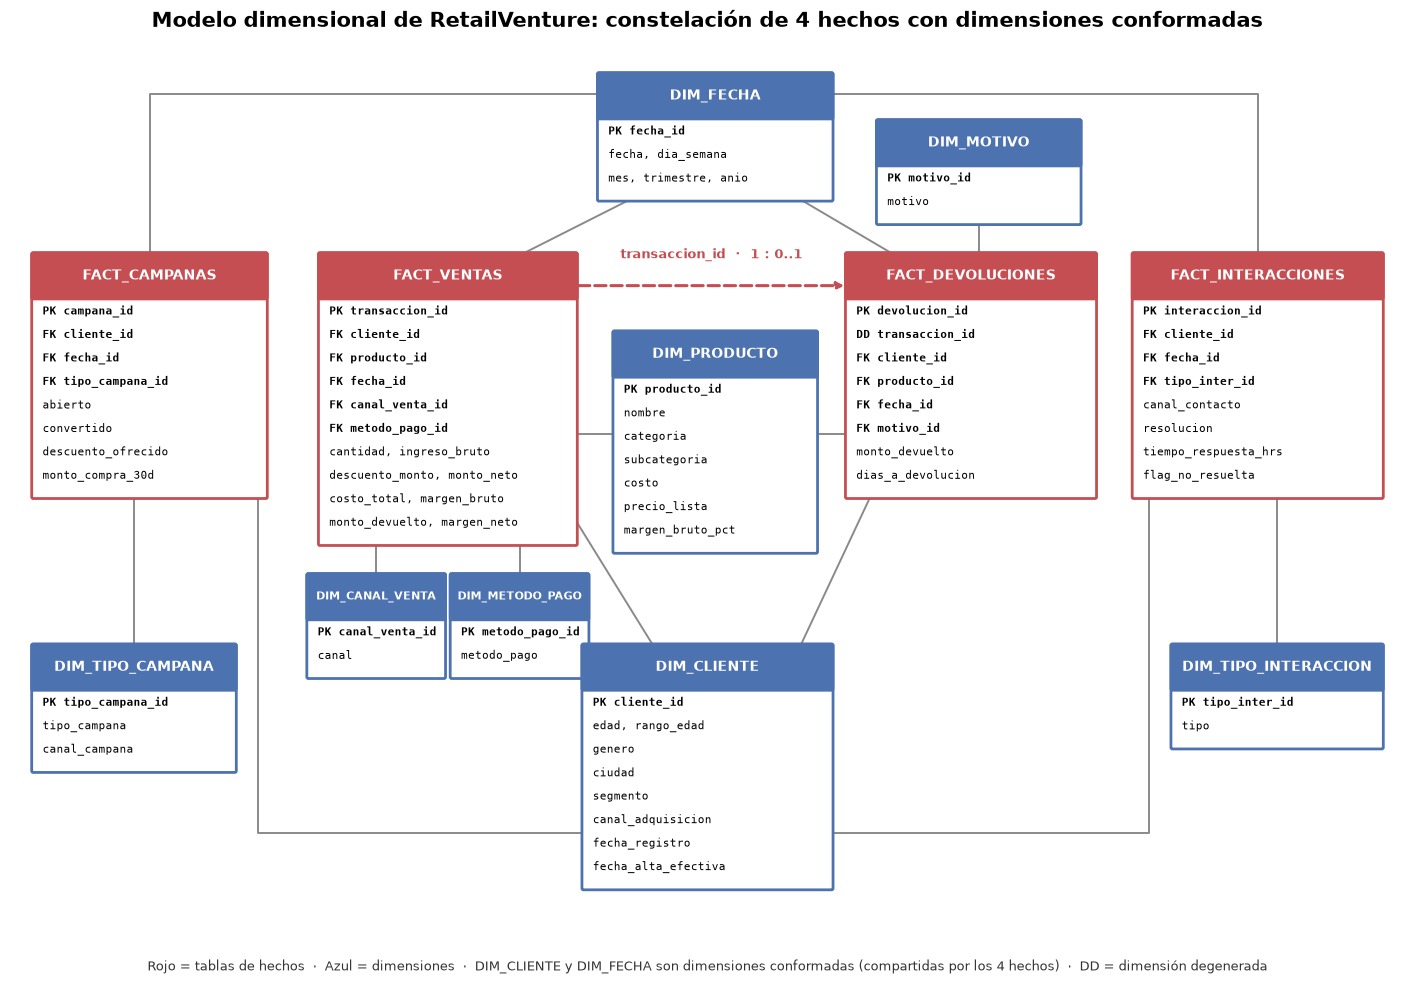

In [21]:
FILA, CAB = 0.30, 0.55
def caja(ax, x, top, w, titulo, campos, color):
    h = CAB + FILA * len(campos) + 0.15
    ax.add_patch(FancyBboxPatch((x, top - h), w, h, boxstyle='round,pad=0.02', fc='white', ec=color, lw=2, zorder=3))
    ax.add_patch(FancyBboxPatch((x, top - CAB), w, CAB, boxstyle='round,pad=0.02', fc=color, ec=color, lw=2, zorder=4))
    ax.text(x + w / 2, top - CAB / 2, titulo, ha='center', va='center', color='white', fontsize=10 if w >= 2.5 else 8, fontweight='bold', zorder=5)
    for k, c_ in enumerate(campos):
        peso = 'bold' if c_.startswith(('PK', 'FK', 'DD')) else 'normal'
        ax.text(x + 0.12, top - CAB - FILA * (k + 0.6), c_, ha='left', va='center', fontsize=8, family='monospace', fontweight=peso, zorder=5)
    return dict(l=x, r=x + w, t=top, b=top - h, cx=x + w / 2, cy=top - h / 2)

def enlace(ax, *pts, color='#8a8a8a', lw=1.4, ls='-'):
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=color, lw=lw, ls=ls, zorder=1, solid_capstyle='round')

F, D = '#C44E52', '#4C72B0'
fig, ax = plt.subplots(figsize=(18, 12.4)); ax.set_xlim(0, 18); ax.set_ylim(0.2, 12.4); ax.axis('off')
# Fila superior
fe = caja(ax, 7.6, 11.9, 3.0, 'DIM_FECHA', ['PK fecha_id', 'fecha, dia_semana', 'mes, trimestre, anio'], D)
mo = caja(ax, 11.2, 11.3, 2.6, 'DIM_MOTIVO', ['PK motivo_id', 'motivo'], D)
# Fila de hechos
fc = caja(ax, 0.3, 9.6, 3.0, 'FACT_CAMPANAS', ['PK campana_id', 'FK cliente_id', 'FK fecha_id', 'FK tipo_campana_id', 'abierto', 'convertido', 'descuento_ofrecido', 'monto_compra_30d'], F)
fv = caja(ax, 4.0, 9.6, 3.3, 'FACT_VENTAS', ['PK transaccion_id', 'FK cliente_id', 'FK producto_id', 'FK fecha_id', 'FK canal_venta_id', 'FK metodo_pago_id', 'cantidad, ingreso_bruto', 'descuento_monto, monto_neto', 'costo_total, margen_bruto', 'monto_devuelto, margen_neto'], F)
dp = caja(ax, 7.8, 8.6, 2.6, 'DIM_PRODUCTO', ['PK producto_id', 'nombre', 'categoria', 'subcategoria', 'costo', 'precio_lista', 'margen_bruto_pct'], D)
fd = caja(ax, 10.8, 9.6, 3.2, 'FACT_DEVOLUCIONES', ['PK devolucion_id', 'DD transaccion_id', 'FK cliente_id', 'FK producto_id', 'FK fecha_id', 'FK motivo_id', 'monto_devuelto', 'dias_a_devolucion'], F)
fi = caja(ax, 14.5, 9.6, 3.2, 'FACT_INTERACCIONES', ['PK interaccion_id', 'FK cliente_id', 'FK fecha_id', 'FK tipo_inter_id', 'canal_contacto', 'resolucion', 'tiempo_respuesta_hrs', 'flag_no_resuelta'], F)
# Fila inferior
tc_ = caja(ax, 0.3, 4.6, 2.6, 'DIM_TIPO_CAMPANA', ['PK tipo_campana_id', 'tipo_campana', 'canal_campana'], D)
cv = caja(ax, 3.85, 5.5, 1.75, 'DIM_CANAL_VENTA', ['PK canal_venta_id', 'canal'], D)
mp = caja(ax, 5.7, 5.5, 1.75, 'DIM_METODO_PAGO', ['PK metodo_pago_id', 'metodo_pago'], D)
cl = caja(ax, 7.4, 4.6, 3.2, 'DIM_CLIENTE', ['PK cliente_id', 'edad, rango_edad', 'genero', 'ciudad', 'segmento', 'canal_adquisicion', 'fecha_registro', 'fecha_alta_efectiva'], D)
ti = caja(ax, 15.0, 4.6, 2.7, 'DIM_TIPO_INTERACCION', ['PK tipo_inter_id', 'tipo'], D)

# DIM_FECHA (conformada) -> los 4 hechos
enlace(ax, (fe['l'], 11.65), (fc['cx'], 11.65), (fc['cx'], fc['t']))
enlace(ax, (fe['r'], 11.65), (fi['cx'], 11.65), (fi['cx'], fi['t']))
enlace(ax, (8.0, fe['b']), (6.6, fv['t']))
enlace(ax, (10.2, fe['b']), (11.4, fd['t']))
# DIM_CLIENTE (conformada) -> los 4 hechos
enlace(ax, (3.2, fc['b']), (3.2, 2.2), (cl['l'], 2.2))
enlace(ax, (fi['l'] + 0.2, fi['b']), (fi['l'] + 0.2, 2.2), (cl['r'], 2.2))
enlace(ax, (fv['r'], 6.2), (8.3, cl['t']))
enlace(ax, (11.1, fd['b']), (10.2, cl['t']))
# Dimensiones propias
enlace(ax, (fv['r'], 7.3), (dp['l'], 7.3)); enlace(ax, (dp['r'], 7.3), (fd['l'], 7.3))
enlace(ax, (cv['cx'], fv['b']), (cv['cx'], cv['t'])); enlace(ax, (mp['cx'], fv['b']), (mp['cx'], mp['t']))
enlace(ax, (12.5, fd['t']), (12.5, mo['b']))
enlace(ax, (1.6, fc['b']), (1.6, tc_['t']))
enlace(ax, (ti['cx'], fi['b']), (ti['cx'], ti['t']))
# Relación entre hechos: venta -> devolución
ax.annotate('', xy=(fd['l'], 9.2), xytext=(fv['r'], 9.2), arrowprops=dict(arrowstyle='-|>', color=F, lw=2.2, ls='--'), zorder=2)
ax.text(9.05, 9.55, 'transaccion_id  ·  1 : 0..1', color=F, fontsize=9, ha='center', fontweight='bold')

ax.text(9, 0.45, 'Rojo = tablas de hechos  ·  Azul = dimensiones  ·  DIM_CLIENTE y DIM_FECHA son dimensiones conformadas (compartidas por los 4 hechos)  ·  DD = dimensión degenerada',
        ha='center', fontsize=9.5, color='#333')
ax.set_title('Modelo dimensional de RetailVenture: constelación de 4 hechos con dimensiones conformadas', fontsize=15, fontweight='bold')
plt.savefig(FIG / 'a1_modelo_dimensional.png', dpi=150, bbox_inches='tight'); plt.show()

**Cardinalidades verificadas en los datos:**
- `dim_cliente 1 : N fact_ventas`: un cliente tiene de 1 a 34 compras; hay 392 clientes sin compras.
- `fact_ventas 1 : 0..1 fact_devoluciones`: cada `transaccion_id` aparece como máximo una vez en devoluciones, y el cliente de la devolución coincide siempre con el de la venta (R10).
- `dim_tipo_campana` absorbe el canal porque cada tipo de campaña usa un único canal (R17: relación funcional `tipo → canal`).
- `dim_producto` se relaciona con `fact_devoluciones` a través de la venta de origen; en el modelo físico se *desnormaliza* `producto_id` en la devolución para no obligar a hacer join entre dos hechos.

In [22]:
assert dev.transaccion_id.is_unique
assert cam.groupby('tipo_campana').canal_campana.nunique().max() == 1
print('Compras por cliente:', trx.groupby('cliente_id').size().agg(['min', 'median', 'max']).to_dict())

Compras por cliente: {'min': 1.0, 'median': 4.0, 'max': 34.0}


## 8. Exportación de datos limpios

In [23]:
dim_fecha = pd.DataFrame({'fecha': pd.date_range(FECHA_INICIO, FECHA_CORTE)})
dim_fecha['fecha_id'] = dim_fecha.fecha.dt.strftime('%Y%m%d').astype(int)
dim_fecha['anio'] = dim_fecha.fecha.dt.year; dim_fecha['trimestre'] = dim_fecha.fecha.dt.quarter
dim_fecha['mes'] = dim_fecha.fecha.dt.month; dim_fecha['anio_mes'] = dim_fecha.fecha.dt.to_period('M').astype(str)
dim_fecha['dia_semana'] = dim_fecha.fecha.dt.dayofweek; dim_fecha['es_fin_semana'] = (dim_fecha.dia_semana >= 5).astype(int)

salidas = {'dim_cliente': cli_c, 'dim_producto': prod_c, 'dim_fecha': dim_fecha, 'fact_ventas': trx_c,
           'fact_devoluciones': dev_c, 'fact_interacciones': crm_c, 'fact_campanas': cam_c}
for n, df in salidas.items():
    df.to_csv(CLEAN / f'{n}.csv', index=False, encoding='utf-8')
pd.DataFrame({n: {'filas': len(df), 'columnas': df.shape[1]} for n, df in salidas.items()}).T

,filas,columnas
dim_cliente,8000,14
dim_producto,318,8
dim_fecha,731,8
fact_ventas,50000,26
fact_devoluciones,6724,13
fact_interacciones,4684,10
fact_campanas,8820,13


## Resumen ejecutivo de A1

1. **Completitud ≈ 100% y unicidad ≈ 100%**: no hay nulos explícitos y hay un solo duplicado lógico. El único nulo disfrazado es `genero = "No especificado"` (5,4%).
2. **Integridad referencial perfecta**: no hay devoluciones sin venta ni registros huérfanos.
3. **Dos campos poco confiables**, documentados y tratados sin perder registros:
   - `clientes.fecha_registro`: el 50% de las compras es anterior al registro → se reemplaza por `fecha_alta_efectiva`.
   - `campanas.convertido`: el 77,5% de las conversiones no tiene compra en 30 días → se complementa con `flag_conversion_verificada`.
4. **Los outliers son legítimos** (ventas de alto valor, casos CRM escalados): se conservan y se marcan.
5. **Contraste con el caso**: la caída de la conversión a la mitad se confirma; la del ticket (−8%) no; las devoluciones (~13,5%) son altas pero **estables**, no crecientes.
6. **Modelo**: constelación de 4 hechos (ventas, devoluciones, interacciones y campañas) con dimensiones conformadas de cliente y fecha.

Los datos limpios quedan en `data/clean/`, y las tablas y figuras de soporte para el informe en `outputs/`.